In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/online_retail_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (392692, 9)


In [37]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 392692 entries, 0 to 392691
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    392692 non-null  int64  
 1   StockCode    392692 non-null  str    
 2   Description  392692 non-null  str    
 3   Quantity     392692 non-null  int64  
 4   InvoiceDate  392692 non-null  str    
 5   UnitPrice    392692 non-null  float64
 6   CustomerID   392692 non-null  int64  
 7   Country      392692 non-null  str    
 8   TotalAmount  392692 non-null  float64
dtypes: float64(2), int64(3), str(4)
memory usage: 27.0 MB


In [39]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
InvoiceNo,392692.0,560590.875047,13087.063759,536365.000,549234.00,561874.00,572061.00,581587.00
Quantity,392692.0,13.119702,180.492832,1.000,2.00,6.00,12.00,80995.00
UnitPrice,392692.0,3.125914,22.241836,0.001,1.25,1.95,3.75,8142.75
CustomerID,392692.0,15287.843865,1713.539549,12346.000,13955.00,15150.00,16791.00,18287.00
TotalAmount,392692.0,22.631500,311.099224,0.001,4.95,12.45,19.80,168469.60


In [40]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["Year"] = df["InvoiceDate"].dt.year
df["Month"] = df["InvoiceDate"].dt.month
df["MonthName"] = df["InvoiceDate"].dt.month_name()
df["Day"] = df["InvoiceDate"].dt.day
df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()
df["Hour"] = df["InvoiceDate"].dt.hour

In [41]:
df[[
    "InvoiceDate",
    "Year",
    "Month",
    "MonthName",
    "DayOfWeek",
    "Hour"
]].head()

,InvoiceDate,Year,Month,MonthName,DayOfWeek,Hour
0,2010-12-01 08:26:00,2010,12,December,Wednesday,8
1,2010-12-01 08:26:00,2010,12,December,Wednesday,8
2,2010-12-01 08:26:00,2010,12,December,Wednesday,8
3,2010-12-01 08:26:00,2010,12,December,Wednesday,8
4,2010-12-01 08:26:00,2010,12,December,Wednesday,8


In [42]:
total_sales = df["TotalAmount"].sum()

print(f"Total Sales: £{total_sales:,.2f}")

Total Sales: £8,887,208.89


In [43]:
total_customers = df["CustomerID"].nunique()

print("Total Customers:", total_customers)

Total Customers: 4338


In [44]:
total_products = df["StockCode"].nunique()

print("Total Products:", total_products)

Total Products: 3665


## Monthly Sales Trend

This analysis examines how total sales changed over time.

In [45]:
monthly_sales = (
    df.groupby(["Year", "Month"])["TotalAmount"]
    .sum()
    .reset_index()
)

monthly_sales["YearMonth"] = (
    monthly_sales["Year"].astype(str)
    + "-"
    + monthly_sales["Month"].astype(str).str.zfill(2)
)

monthly_sales

,Year,Month,TotalAmount,YearMonth
0,2010,12,570422.730,2010-12
1,2011,1,568101.310,2011-01
2,2011,2,446084.920,2011-02
3,2011,3,594081.760,2011-03
4,2011,4,468374.331,2011-04
5,2011,5,677355.150,2011-05
6,2011,6,660046.050,2011-06
7,2011,7,598962.901,2011-07
8,2011,8,644051.040,2011-08
9,2011,9,950690.202,2011-09


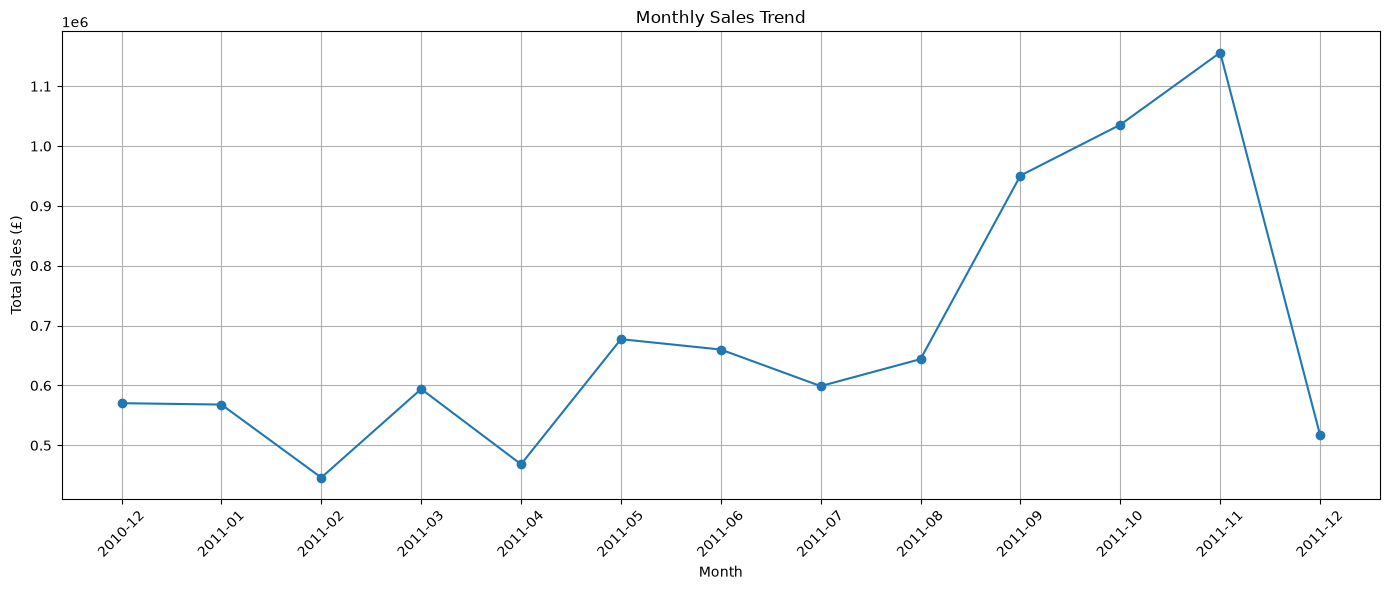

In [46]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["YearMonth"],
    monthly_sales["TotalAmount"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "../visualizations/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
country_sales = (
    df.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
)

country_sales.head(10)

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: TotalAmount, dtype: float64

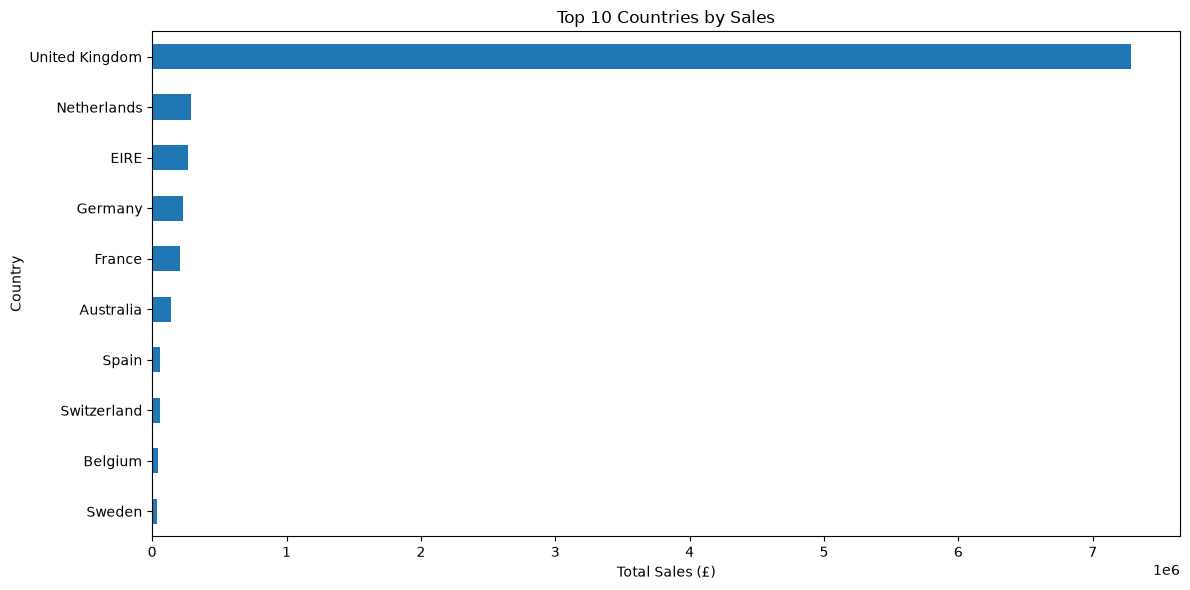

In [48]:
plt.figure(figsize=(12, 6))

country_sales.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Sales")
plt.xlabel("Total Sales (£)")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig(
    "../visualizations/top_countries_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [49]:
product_sales = (
    df.groupby("Description")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
)

product_sales.head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: TotalAmount, dtype: float64

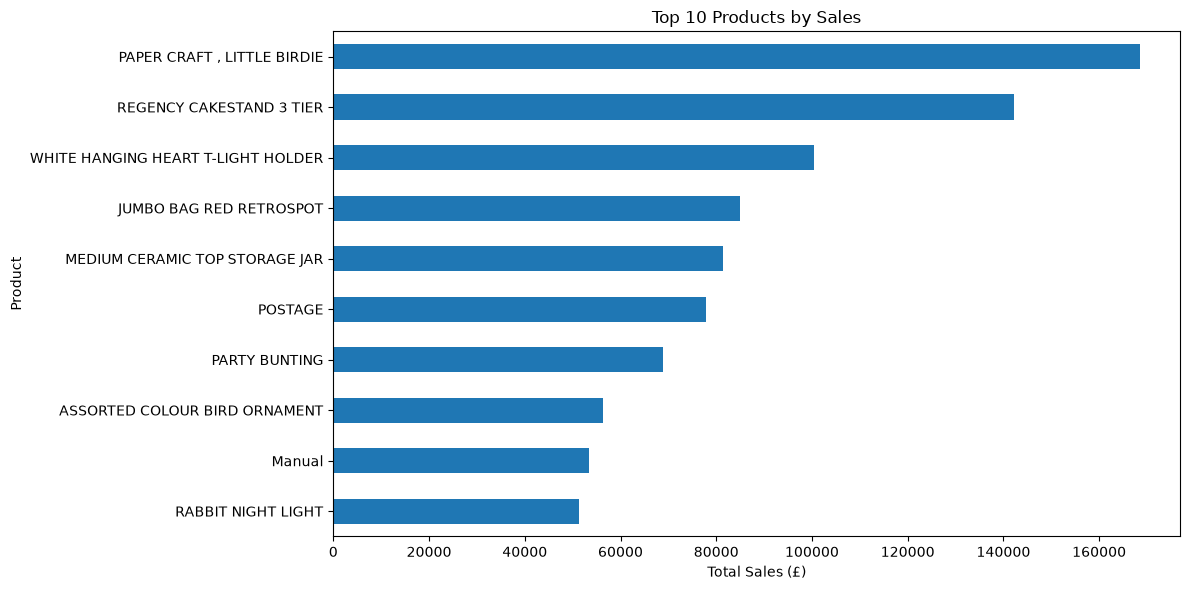

In [50]:
plt.figure(figsize=(12, 6))

product_sales.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales (£)")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig(
    "../visualizations/top_products_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

daily_sales = (
    df.groupby("DayOfWeek")["TotalAmount"]
    .sum()
    .reindex(day_order)
)

daily_sales

DayOfWeek
Monday       1363604.401
Tuesday      1697733.801
Wednesday    1584283.830
Thursday     1973015.730
Friday       1483080.811
Saturday             NaN
Sunday        785490.321
Name: TotalAmount, dtype: float64

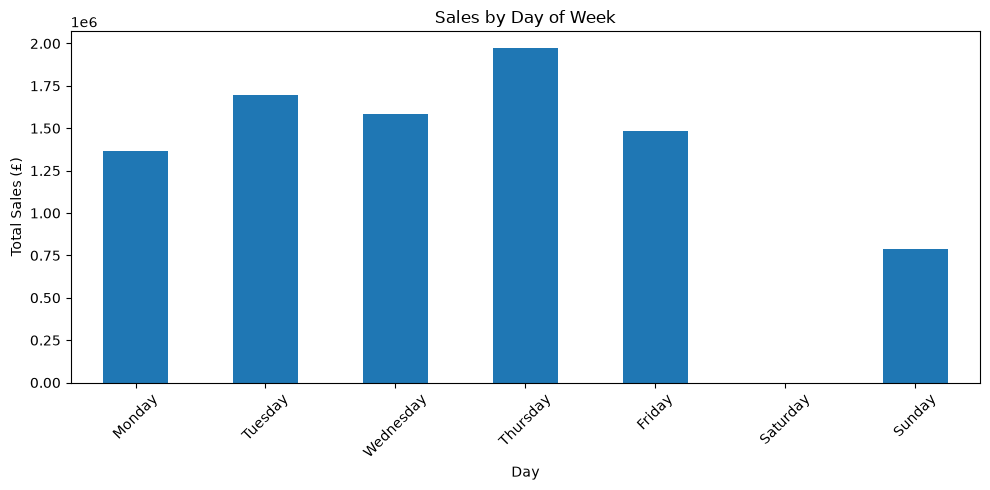

In [52]:
plt.figure(figsize=(10, 5))

daily_sales.plot(kind="bar")

plt.title("Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Total Sales (£)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../visualizations/sales_by_day.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

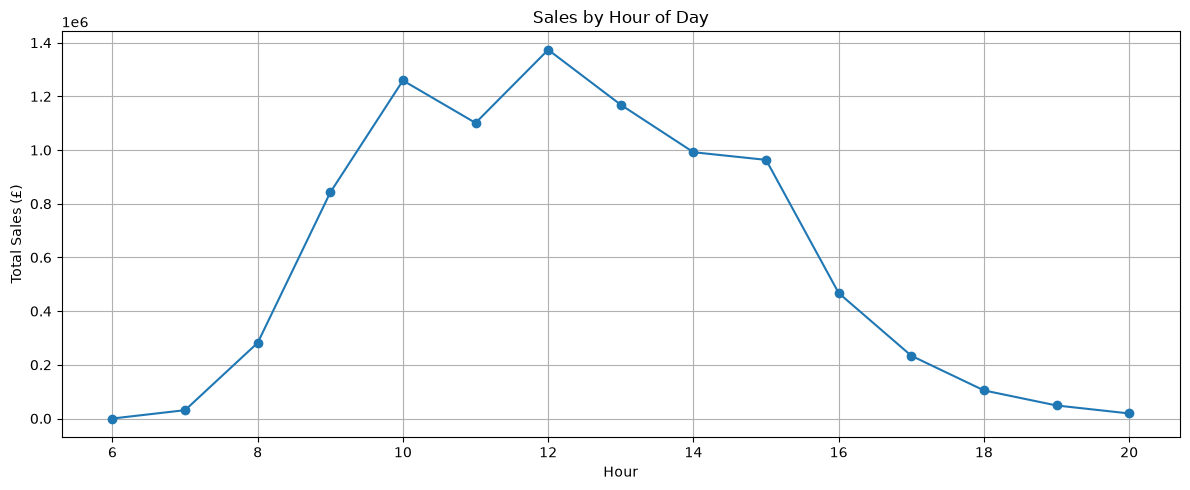

In [53]:
hourly_sales = df.groupby("Hour")["TotalAmount"].sum()

plt.figure(figsize=(12, 5))

hourly_sales.plot(kind="line", marker="o")

plt.title("Sales by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Total Sales (£)")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "../visualizations/sales_by_hour.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [54]:
customer_sales = (
    df.groupby("CustomerID")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Customers by Total Spending:")
print(customer_sales.head(10))

Top 10 Customers by Total Spending:
CustomerID
14646    280206.02
18102    259657.30
17450    194390.79
16446    168472.50
14911    143711.17
12415    124914.53
14156    117210.08
17511     91062.38
16029     80850.84
12346     77183.60
Name: TotalAmount, dtype: float64


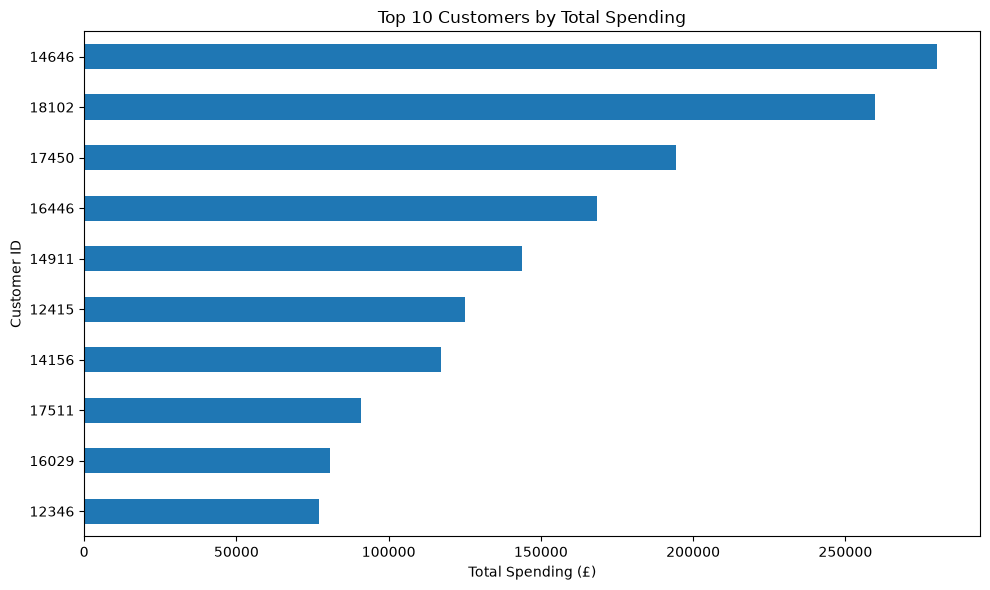

In [55]:
plt.figure(figsize=(10, 6))

customer_sales.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Total Spending (£)")
plt.ylabel("Customer ID")
plt.tight_layout()

plt.savefig(
    "../visualizations/top_customers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [56]:
customer_frequency = (
    df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Customers by Number of Purchases:")
print(customer_frequency.head(10))

Top 10 Customers by Number of Purchases:
CustomerID
12748    209
14911    201
17841    124
13089     97
14606     93
15311     91
12971     86
14646     73
16029     63
13408     62
Name: InvoiceNo, dtype: int64


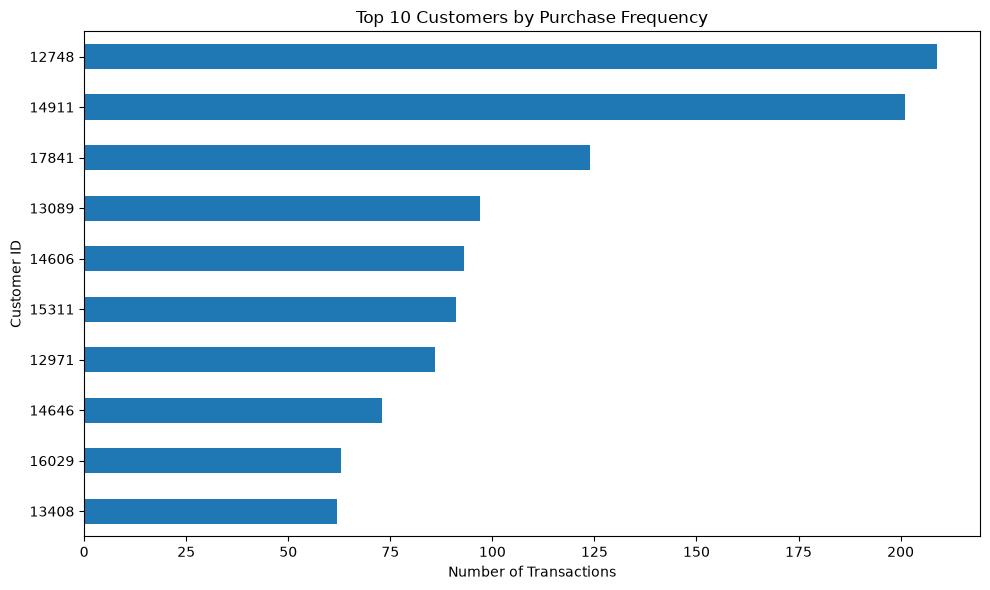

In [57]:
plt.figure(figsize=(10, 6))

customer_frequency.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Purchase Frequency")
plt.xlabel("Number of Transactions")
plt.ylabel("Customer ID")
plt.tight_layout()

plt.savefig(
    "../visualizations/top_customers_frequency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [58]:
invoice_sales = (
    df.groupby("InvoiceNo")["TotalAmount"]
    .sum()
)

average_order_value = invoice_sales.mean()

print(f"Average Order Value: £{average_order_value:,.2f}")

Average Order Value: £479.56


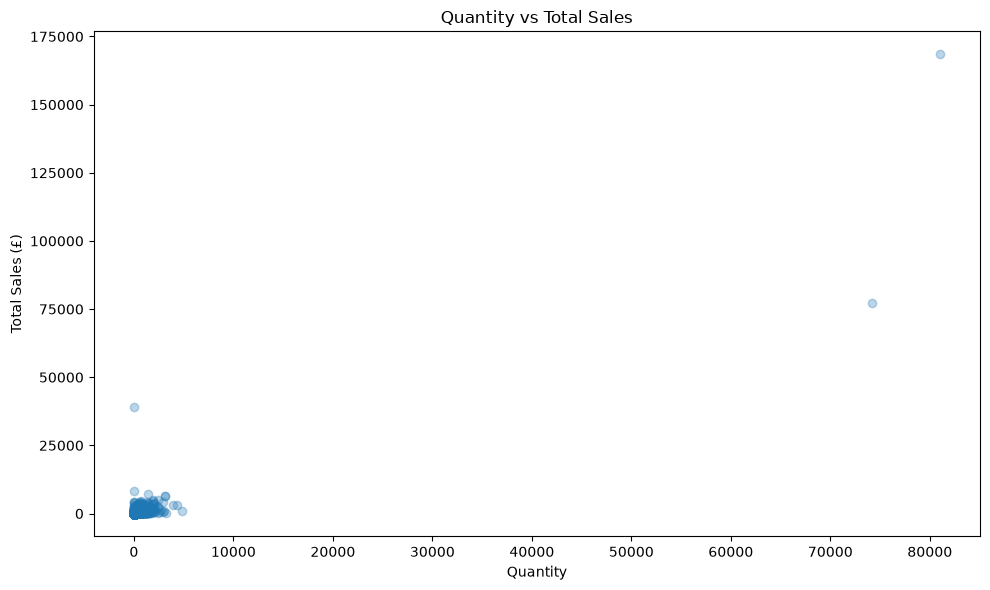

In [59]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Quantity"],
    df["TotalAmount"],
    alpha=0.3
)

plt.title("Quantity vs Total Sales")
plt.xlabel("Quantity")
plt.ylabel("Total Sales (£)")
plt.tight_layout()

plt.savefig(
    "../visualizations/quantity_vs_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [60]:
numeric_columns = [
    "Quantity",
    "UnitPrice",
    "TotalAmount",
    "Year",
    "Month",
    "Hour"
]

correlation = df[numeric_columns].corr()

print(correlation)

             Quantity  UnitPrice  TotalAmount      Year     Month      Hour
Quantity     1.000000  -0.004578     0.914451  0.001469 -0.004040 -0.014665
UnitPrice   -0.004578   1.000000     0.081619 -0.000203 -0.005063 -0.000217
TotalAmount  0.914451   0.081619     1.000000  0.000349 -0.002562 -0.013093
Year         0.001469  -0.000203     0.000349  1.000000 -0.340599 -0.019772
Month       -0.004040  -0.005063    -0.002562 -0.340599  1.000000  0.058442
Hour        -0.014665  -0.000217    -0.013093 -0.019772  0.058442  1.000000


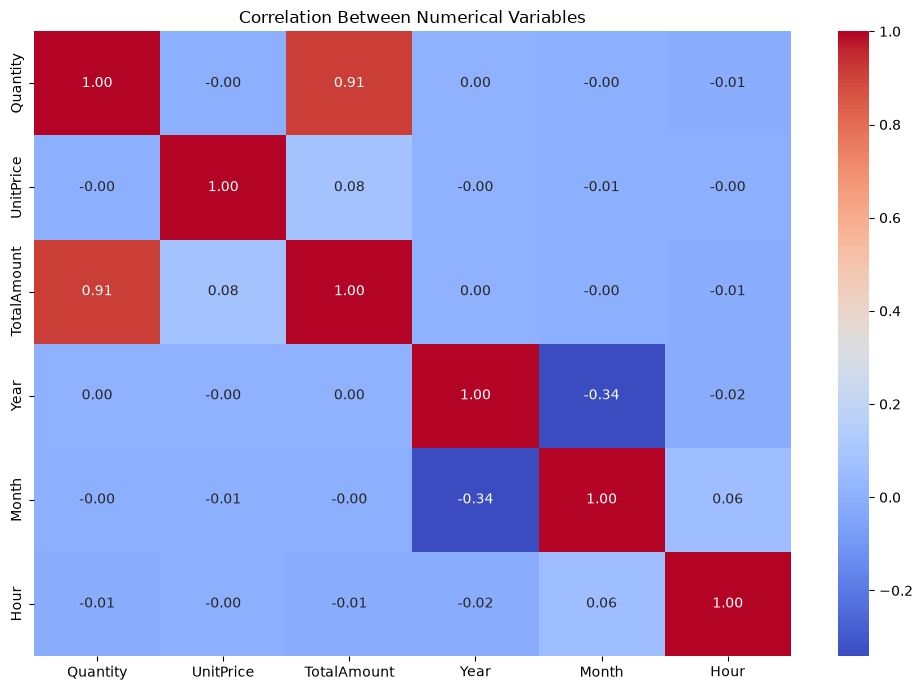

In [61]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()

plt.savefig(
    "../visualizations/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Feature Engineering

Transaction-level records are converted into customer-level features
for machine learning.

In [62]:
customer_features = df.groupby("CustomerID").agg(
    TotalSpent=("TotalAmount", "sum"),
    TotalOrders=("InvoiceNo", "nunique"),
    TotalItems=("Quantity", "sum"),
    AverageOrderValue=("TotalAmount", "mean"),
    AverageUnitPrice=("UnitPrice", "mean"),
    UniqueProducts=("StockCode", "nunique"),
    UniqueCountries=("Country", "nunique")
).reset_index()

customer_features.head()

,CustomerID,TotalSpent,TotalOrders,TotalItems,AverageOrderValue,AverageUnitPrice,UniqueProducts,UniqueCountries
0,12346,77183.60,1,74215,77183.600000,1.040000,1,1
1,12347,4310.00,7,2458,23.681319,2.644011,103,1
2,12348,1797.24,4,2341,57.975484,5.764839,22,1
3,12349,1757.55,1,631,24.076027,8.289041,73,1
4,12350,334.40,1,197,19.670588,3.841176,17,1


In [63]:
print("Customer dataset shape:", customer_features.shape)
print("\nData types:")
print(customer_features.dtypes)

Customer dataset shape: (4338, 8)

Data types:
CustomerID             int64
TotalSpent           float64
TotalOrders            int64
TotalItems             int64
AverageOrderValue    float64
AverageUnitPrice     float64
UniqueProducts         int64
UniqueCountries        int64
dtype: object


In [64]:
customer_features.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,4338.0,15300.408022,1721.808492,12346.00000,13813.250000,15299.500000,16778.750000,18287.00
TotalSpent,4338.0,2048.688081,8985.230220,3.75000,306.482500,668.570000,1660.597500,280206.02
TotalOrders,4338.0,4.272015,7.697998,1.00000,1.000000,2.000000,5.000000,209.00
TotalItems,4338.0,1187.644537,5043.619654,1.00000,159.000000,378.000000,989.750000,196915.00
AverageOrderValue,4338.0,68.381590,1467.918294,2.13697,12.393196,17.755000,24.878950,77183.60
AverageUnitPrice,4338.0,4.470820,34.215024,0.12250,2.206415,2.917836,3.832541,2033.10
UniqueProducts,4338.0,61.501153,85.366768,1.00000,16.000000,35.000000,77.000000,1787.00
UniqueCountries,4338.0,1.001844,0.042909,1.00000,1.000000,1.000000,1.000000,2.00


In [65]:
threshold = customer_features["TotalSpent"].quantile(0.75)

print(f"High-value customer threshold: £{threshold:,.2f}")

High-value customer threshold: £1,660.60


In [66]:
customer_features["HighValueCustomer"] = (
    customer_features["TotalSpent"] >= threshold
).astype(int)

In [67]:
print(
    customer_features["HighValueCustomer"]
    .value_counts()
)

HighValueCustomer
0    3253
1    1085
Name: count, dtype: int64


In [68]:
print(
    customer_features["HighValueCustomer"]
    .value_counts(normalize=True) * 100
)

HighValueCustomer
0    74.988474
1    25.011526
Name: proportion, dtype: float64


In [69]:
customer_features.to_csv(
    "../data/processed/customer_features.csv",
    index=False
)

print("Customer feature dataset saved successfully!")

Customer feature dataset saved successfully!
